# 03 · Asociación: odds ratios crudos y ajustados (OE2 · H-1) y tamaño de muestra

**Rúbrica D y G.** Se ajustan modelos de regresión logística por máxima verosimilitud (`statsmodels`):

- **Crudo:** cada variable por separado.
- **Básico:** consulta + ECG de reposo + prueba de esfuerzo (11 variables).
- **Extendido:** el básico más fluoroscopia (`ca`) y gammagrafía con talio (`thal`).

**H-1.** H0: todos los β del modelo básico son 0; H1: al menos uno es distinto de 0 (razón de verosimilitud global).

**Supuestos verificados:** linealidad del logit (Box-Tidwell), colinealidad (VIF), bondad de ajuste (Hosmer-Lemeshow) y observaciones influyentes (distancia de Cook).

In [1]:
%run ./00_configuracion.ipynb
from statsmodels.stats.outliers_influence import variance_inflation_factor
df, cc = load_processed()

In [2]:
def fit_logit(df, predictors):
    X = design_matrix(df, predictors)
    for v, u in OR_UNITS.items():  # reescala para OR por unidad clínica
        if v in X:
            X[v] = X[v] / u
    X = sm.add_constant(X)
    model = sm.Logit(df["ec"].astype(float), X).fit(disp=0, maxiter=200)
    return model, X


def or_table(model):
    ci = model.conf_int(alpha=ALPHA)
    t = pd.DataFrame({
        "termino": model.params.index, "beta": model.params.values,
        "ee": model.bse.values, "OR": np.exp(model.params.values),
        "IC95_inf": np.exp(ci[0].values), "IC95_sup": np.exp(ci[1].values),
        "z": model.tvalues.values, "p": model.pvalues.values})
    t = t[t.termino != "const"].reset_index(drop=True)
    t["etiqueta"] = t["termino"].map(term_label)
    return t


def crude_ors(df, predictors):
    """OR crudo de cada predictor (regresión logística univariable)."""
    out = []
    for v in predictors:
        sub = df.dropna(subset=[v])
        m, _ = fit_logit(sub, [v])
        t = or_table(m)
        t["n"] = len(sub)
        out.append(t)
    return pd.concat(out, ignore_index=True)


def hosmer_lemeshow(y, p, g=10):
    d = pd.DataFrame({"y": y, "p": p})
    d["grupo"] = pd.qcut(d["p"].rank(method="first"), g, labels=False)
    agg = d.groupby("grupo").agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    hl = (((agg.obs - agg.esp) ** 2) / (agg.esp * (1 - agg.esp / agg.n))).sum()
    return float(hl), float(stats.chi2.sf(hl, g - 2))


def box_tidwell(df, predictors):
    """Linealidad del logit: añade x·ln(x) para cada continua; p < 0,05 sugiere no linealidad."""
    out = {}
    for v in CONTINUOUS:
        if v not in predictors:
            continue
        d = df.copy()
        x = d[v].astype(float) + (1.0 if (d[v] <= 0).any() else 0.0)  # oldpeak tiene ceros
        X = design_matrix(d, predictors)
        X[f"{v}_lnx"] = x * np.log(x)
        X = sm.add_constant(X)
        m = sm.Logit(d["ec"].astype(float), X).fit(disp=0, maxiter=200)
        out[v] = float(m.pvalues[f"{v}_lnx"])
    return out


def vif(X):
    Xc = X.drop(columns="const")
    Xc = sm.add_constant(Xc)
    return {col: float(variance_inflation_factor(Xc.values, i))
            for i, col in enumerate(Xc.columns) if col != "const"}


def influence(df, X):
    glm = sm.GLM(df["ec"].astype(float), X, family=sm.families.Binomial()).fit()
    cooks = glm.get_influence().cooks_distance[0]
    thr = 4 / len(df)
    return {"umbral_cook_4_n": thr, "n_influyentes": int((cooks > thr).sum()),
            "cook_max": float(cooks.max()), "ids_influyentes": df["id"][cooks > thr].tolist()}


def nagelkerke(model):
    n = model.nobs
    r2cs = 1 - np.exp((2 / n) * (model.llnull - model.llf))
    r2max = 1 - np.exp((2 / n) * model.llnull)
    return float(r2cs), float(r2cs / r2max)


def explanatory_model(df, predictors, name):
    sub = df.dropna(subset=predictors).copy()
    model, X = fit_logit(sub, predictors)
    hl, hl_p = hosmer_lemeshow(sub["ec"].values, model.predict(X).values)
    r2cs, r2n = nagelkerke(model)
    diag = {
        "modelo": name, "n": int(model.nobs), "eventos": int(sub["ec"].sum()),
        "parametros": int(len(model.params) - 1),
        "epv": float(sub["ec"].sum() / (len(model.params) - 1)),
        "log_verosimilitud": float(model.llf), "llnull": float(model.llnull),
        "LR_chi2": float(model.llr), "LR_gl": int(model.df_model), "LR_p": float(model.llr_pvalue),
        "AIC": float(model.aic), "BIC": float(model.bic),
        "R2_McFadden": float(model.prsquared), "R2_CoxSnell": r2cs, "R2_Nagelkerke": r2n,
        "Hosmer_Lemeshow_chi2": hl, "Hosmer_Lemeshow_p": hl_p,
        "VIF": vif(X), "VIF_max": max(vif(X).values()),
        "Box_Tidwell_p": box_tidwell(sub, predictors),
        "influencia": influence(sub, X),
        "convergio": bool(model.mle_retvals["converged"]),
    }
    return model, or_table(model), diag


def lr_test(m_small, m_big):
    stat = 2 * (m_big.llf - m_small.llf)
    gl = int(m_big.df_model - m_small.df_model)
    return {"LR_chi2": float(stat), "gl": gl, "p": float(stats.chi2.sf(stat, gl))}

## Ajuste de los modelos

In [3]:
crude = crude_ors(cc, PRED_EXTENDIDO)
m_b, or_b, diag_b = explanatory_model(cc, PRED_BASICO, "básico")
m_e, or_e, diag_e = explanatory_model(cc, PRED_EXTENDIDO, "extendido")
m_b303, or_b303, diag_b303 = explanatory_model(df, PRED_BASICO, "básico n=303 (sensibilidad)")
lr_be = lr_test(m_b, m_e)
print(m_b.summary())

                           Logit Regression Results                           
Dep. Variable:                     ec   No. Observations:                  297
Model:                          Logit   Df Residuals:                      282
Method:                           MLE   Df Model:                           14
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.4262
Time:                        12:05:57   Log-Likelihood:                -117.62
converged:                       True   LL-Null:                       -204.97
Covariance Type:            nonrobust   LLR p-value:                 7.633e-30
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -6.2400      2.543     -2.453      0.014     -11.225      -1.255
age                 0.2258      0.215      1.049      0.294      -0.196       0.648
sex                 2.0122      

## Tabla 2. OR crudos y ajustados

In [4]:
merged = (fmt_or(crude)[["termino", "etiqueta", "OR (IC 95 %)", "p_fmt"]]
          .merge(fmt_or(or_b)[["termino", "OR (IC 95 %)", "p_fmt"]], on="termino", how="left", suffixes=("", "_b"))
          .merge(fmt_or(or_e)[["termino", "OR (IC 95 %)", "p_fmt"]], on="termino", how="left", suffixes=("", "_e"))).fillna("—")
merged.columns = ["termino", "Variable", "OR crudo (IC 95 %)", "p crudo",
                  "OR ajustado básico (IC 95 %)", "p básico", "OR ajustado extendido (IC 95 %)", "p extendido"]
merged.to_csv(TABLES / "tabla2_odds_ratios.csv", index=False)
to_latex(merged.drop(columns="termino"), TABLES / "tabla2_odds_ratios.tex",
         "Odds ratios crudos y ajustados (regresión logística por máxima verosimilitud).", "tab:or")
for name, t in [("crudo", crude), ("basico", or_b), ("extendido", or_e), ("basico_n303", or_b303)]:
    t.to_csv(TABLES / f"or_{name}_detalle.csv", index=False)
display(merged.drop(columns="termino"))

,Variable,OR crudo (IC 95 %),p crudo,OR ajustado básico (IC 95 %),p básico,OR ajustado extendido (IC 95 %),p extendido
0,Edad (por 10 años),"1,70 (1,29–2,23)","< 0,001","1,25 (0,82–1,91)","0,294","0,87 (0,54–1,42)","0,580"
1,Sexo masculino,"3,57 (2,10–6,10)","< 0,001","7,48 (3,25–17,20)","< 0,001","4,66 (1,66–13,08)","0,003"
2,Tipo de dolor torácico: Angina atípica (vs. an...,"0,51 (0,16–1,62)","0,255","2,68 (0,66–10,81)","0,166","3,47 (0,77–15,69)","0,107"
3,Tipo de dolor torácico: Dolor no anginoso (vs....,"0,63 (0,23–1,77)","0,384","1,47 (0,44–4,96)","0,533","1,28 (0,35–4,71)","0,705"
4,Tipo de dolor torácico: Asintomático (vs. angi...,"6,04 (2,31–15,79)","< 0,001","10,60 (3,17–35,40)","< 0,001","8,08 (2,19–29,83)","0,002"
5,Presión arterial sistólica en reposo (por 10 m...,"1,19 (1,05–1,36)","0,009","1,21 (0,99–1,47)","0,059","1,28 (1,02–1,59)","0,029"
6,Colesterol sérico total (por 40 mg/dL),"1,13 (0,95–1,36)","0,170","1,21 (0,92–1,58)","0,175","1,19 (0,87–1,63)","0,268"
7,Glucemia en ayunas > 120 mg/dL,"1,02 (0,53–1,95)","0,956","0,94 (0,36–2,42)","0,894","0,55 (0,17–1,81)","0,325"
8,ECG en reposo anormal (ST-T o HVI),"2,02 (1,27–3,21)","0,003","1,46 (0,75–2,84)","0,259","1,61 (0,76–3,41)","0,210"
9,Frecuencia cardíaca máxima alcanzada (por 10 lpm),"0,64 (0,56–0,73)","< 0,001","0,82 (0,68–1,00)","0,048","0,84 (0,67–1,04)","0,107"


## Diagnósticos del modelo y prueba de H-1

In [5]:
keys = ["n", "eventos", "parametros", "epv", "LR_chi2", "LR_gl", "LR_p", "AIC", "R2_Nagelkerke",
        "Hosmer_Lemeshow_p", "VIF_max", "convergio"]
display(pd.DataFrame({d["modelo"]: {k: d[k] for k in keys} for d in (diag_b, diag_e, diag_b303)}))
print("Box-Tidwell (p) modelo básico:", {k: round(v, 3) for k, v in diag_b["Box_Tidwell_p"].items()})
print("Observaciones influyentes (Cook > 4/n), modelo básico:", diag_b["influencia"]["n_influyentes"])
print("Razón de verosimilitud básico vs. extendido:", lr_be)

,básico,extendido,básico n=303 (sensibilidad)
n,297,297,303
eventos,137,137,139
parametros,14,17,14
epv,9.785714,8.058824,9.928571
LR_chi2,174.712088,218.285182,180.707097
LR_gl,14,17,14
LR_p,0.0,0.0,0.0
AIC,265.234408,227.661314,267.275041
R2_Nagelkerke,0.594133,0.695367,0.600309
Hosmer_Lemeshow_p,0.532457,0.647841,0.456799


Box-Tidwell (p) modelo básico: {'age': 0.366, 'trestbps': 0.822, 'chol': 0.452, 'thalach': 0.984, 'oldpeak': 0.224}
Observaciones influyentes (Cook > 4/n), modelo básico: 23
Razón de verosimilitud básico vs. extendido: {'LR_chi2': 43.57309400221146, 'gl': 3, 'p': 1.859587871210887e-09}


**Interpretación.**
- **H-1:** la razón de verosimilitud global tiene p < 0,001, así que se rechaza H0.
- **Supuestos:** Box-Tidwell no muestra violaciones de linealidad (todos los p > 0,05), el VIF es < 5 y Hosmer-Lemeshow no detecta mal ajuste.
- **Predictores independientes sólidos del modelo básico:** sexo masculino, dolor torácico asintomático y depresión del ST inducida por ejercicio (p ≤ 0,003, estables con n = 297 y n = 303).
- **Frecuencia cardíaca máxima:** el efecto es protector (OR ≈ 0,82 por cada 10 lpm), pero **limítrofe**. Pasa de p = 0,048 (n = 297) a p = 0,051 (n = 303), así que debe interpretarse con cautela: la dirección del efecto es consistente, pero la evidencia es débil una vez se ajusta por las demás variables de la prueba de esfuerzo.
- **Efectos que se pierden al ajustar:** la edad, la angina de esfuerzo y la pendiente del ST son significativas en el análisis crudo, pero no en el ajustado. Esto es coherente con confusión por sexo y por variables de esfuerzo correlacionadas (la angina de esfuerzo y la depresión del ST comparten información, como muestra la figura 5).
- **Colesterol:** no se asocia con la EC ni en el OR crudo (p = 0,170) ni en el ajustado (p = 0,175). Solo hay una diferencia marginal de medianas (p = 0,047, Tabla 1). Es plausible por ser una cohorte remitida (sesgo de espectro) y por la falta de datos sobre uso de estatinas.
- **Análisis de sensibilidad (n = 303):** reproduce las mismas estimaciones puntuales (diferencias < 0,02 en los OR principales).


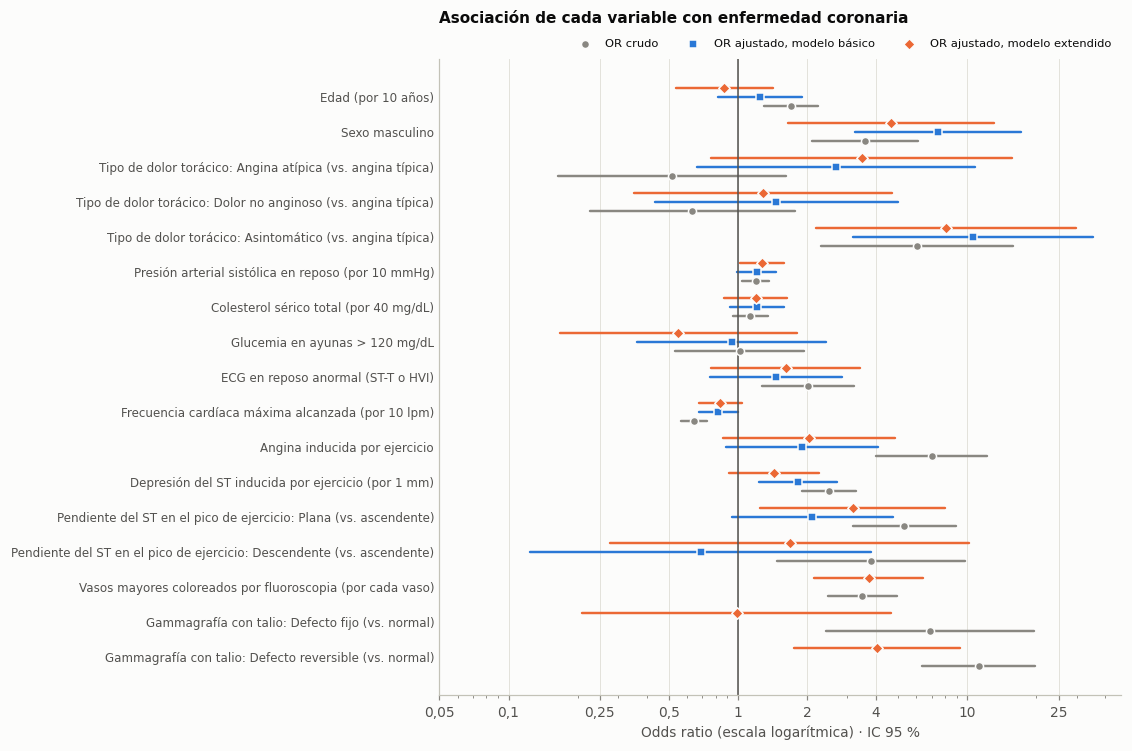

In [6]:
def fig_forest(crude, adj_b, adj_e):
    setup()
    terms = list(adj_e.termino)
    labels = adj_e.set_index("termino")["etiqueta"]
    series = [("OR crudo", crude, K["crudo"], "o", -0.25),
              ("OR ajustado, modelo básico", adj_b, K["m_basico"], "s", 0.0),
              ("OR ajustado, modelo extendido", adj_e, K["m_extendido"], "D", 0.25)]
    fig, ax = plt.subplots(figsize=(8, 7.5))
    ys = np.arange(len(terms))[::-1]
    for name, t, col, mk, off in series:
        t = t.set_index("termino")
        for y, term in zip(ys, terms):
            if term not in t.index:
                continue
            r = t.loc[term]
            ax.plot([r.IC95_inf, r.IC95_sup], [y + off, y + off], color=col, lw=1.6, solid_capstyle="round")
            ax.scatter(r.OR, y + off, marker=mk, s=28, color=col, edgecolor=K["surface"], linewidth=1, zorder=3,
                       label=name if term == terms[0] else None)
    ax.axvline(1, color=K["ink2"], lw=1)
    ax.set_xscale("log")
    ax.set_xticks([0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 25], ["0,05", "0,1", "0,25", "0,5", "1", "2", "4", "10", "25"])
    ax.set_yticks(ys, [labels[t] for t in terms], fontsize=7.8)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Odds ratio (escala logarítmica) · IC 95 %")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=3, fontsize=7.5)
    ax.set_title("Asociación de cada variable con enfermedad coronaria", pad=24)
    save(fig, "fig06_forest_odds_ratios")


fig_forest(crude, or_b, or_e)

## Justificación del tamaño de muestra (Riley *et al.*, BMJ 2020)

Criterios para modelos de predicción binarios:
1. Contracción ≥ 0,90.
2. Optimismo del R² de Nagelkerke ≤ 0,05.
3. Precisión de ± 0,05 en la prevalencia.

El R² de Cox-Snell se anticipa a partir de un AUC plausible según la literatura (0,80 para el modelo básico y 0,85 para el extendido).

In [7]:
def riley_sample_size(prevalence, n_params, auc_anticipated, shrinkage=0.9, margin=0.05):
    """Criterios 1-3 de Riley et al. (2020). R²_CS se anticipa desde el AUC
    usando la aproximación de Riley et al. (2021, Stat Med) vía simulación."""
    phi = prevalence
    ln_null = phi * np.log(phi) + (1 - phi) * np.log(1 - phi)
    r2_max = 1 - np.exp(2 * ln_null)
    # Aproximación de R²_CS a partir del AUC (simulación con predictor latente normal)
    rng = np.random.default_rng(SEED)
    d = np.sqrt(2) * stats.norm.ppf(auc_anticipated)
    nsim = 1_000_000
    y = rng.random(nsim) < phi
    lp = rng.normal(0, 1, nsim) + d * y
    # Ajuste logístico rápido sobre el predictor latente
    m = sm.Logit(y.astype(float), sm.add_constant(lp[:, None])).fit(disp=0)
    r2cs = 1 - np.exp((2 / nsim) * (m.llnull - m.llf))
    n1 = n_params / ((shrinkage - 1) * np.log(1 - r2cs / shrinkage))
    s_adj = r2cs / (r2cs + 0.05 * r2_max)  # criterio 2: optimismo de R²_Nagelkerke ≤ 0,05
    n2 = n_params / ((s_adj - 1) * np.log(1 - r2cs / s_adj))
    n3 = (stats.norm.ppf(1 - ALPHA / 2) / margin) ** 2 * phi * (1 - phi)
    n_req = int(np.ceil(max(n1, n2, n3)))
    return {"prevalencia": phi, "parametros": n_params, "auc_anticipado": auc_anticipated,
            "R2_CS_anticipado": float(r2cs), "R2_CS_max": float(r2_max),
            "n_criterio1_shrinkage": int(np.ceil(n1)), "n_criterio2_optimismo": int(np.ceil(n2)),
            "n_criterio3_prevalencia": int(np.ceil(n3)), "n_requerido": n_req,
            "eventos_requeridos": int(np.ceil(n_req * phi)),
            "epv_requerido": float(n_req * phi / n_params)}


def margin_achieved(prevalence, n):
    return float(stats.norm.ppf(1 - ALPHA / 2) * np.sqrt(prevalence * (1 - prevalence) / n))


ss = {"basico": riley_sample_size(cc.ec.mean(), diag_b["parametros"], 0.80),
      "extendido": riley_sample_size(cc.ec.mean(), diag_e["parametros"], 0.85),
      "margen_prevalencia_alcanzado": margin_achieved(cc.ec.mean(), len(cc))}
display(pd.DataFrame({k: v for k, v in ss.items() if isinstance(v, dict)}))
print(f"Margen alcanzado en la prevalencia: ± {100 * ss['margen_prevalencia_alcanzado']:.1f} %")

,basico,extendido
prevalencia,0.461279,0.461279
parametros,14.000000,17.000000
auc_anticipado,0.800000,0.850000
R2_CS_anticipado,0.259516,0.345702
R2_CS_max,0.748495,0.748495
n_criterio1_shrinkage,412.000000,351.000000
n_criterio2_optimismo,316.000000,361.000000
n_criterio3_prevalencia,382.000000,382.000000
n_requerido,412.000000,382.000000
eventos_requeridos,191.000000,177.000000


Margen alcanzado en la prevalencia: ± 5.7 %


**Interpretación.** La muestra (n = 297) es inferior a la recomendada (≈ 380–410). Se declara como limitación y se mitiga con
penalización L2, validación cruzada repetida, corrección de optimismo por bootstrap y el reporte de la pendiente de calibración (notebook 04).

In [8]:
save_json("03_asociacion", {
    "modelo_explicativo": {
        "basico": diag_b, "extendido": diag_e, "basico_n303": diag_b303, "LR_basico_vs_extendido": lr_be,
        "OR_basico": or_b.set_index("termino")[["OR", "IC95_inf", "IC95_sup", "p"]].to_dict("index"),
        "OR_extendido": or_e.set_index("termino")[["OR", "IC95_inf", "IC95_sup", "p"]].to_dict("index"),
        "OR_crudo": crude.set_index("termino")[["OR", "IC95_inf", "IC95_sup", "p"]].to_dict("index")},
    "tamano_muestra": ss})

PosixPath('/home/ana/code/Semestre_4/Healtech_1/Proyecto/results/json/03_asociacion.json')